<a href="https://colab.research.google.com/github/lamaljalal/NLP/blob/main/Lab12_Transformers.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Transformers


#### A Transformer is a deep learning architecture designed to process sequences of text using self-attention.

- Transformers are the foundation of many modern NLP models, including BERT, GPT, and T5.

- Before Transformers, we used models such as RNNs and LSTMs for NLP tasks.

<img src="https://drive.google.com/thumbnail?id=1unPqGaKftHxp37-F99Bg6hJzFbQdCGC7&sz=w1000" width="700">

In [1]:
%pip -q install transformers torch matplotlib

## 1. Load a Transformer

We use **DistilBERT**, a  Transformer fine-tuned for positive/negative sentiment classification.

In [2]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
import torch

model_name = "distilbert-base-uncased-finetuned-sst-2-english"

tokenizer = AutoTokenizer.from_pretrained(model_name)

model = AutoModelForSequenceClassification.from_pretrained(model_name)
model.eval()

# Look inside the Transformer architecture.
print("Transformer layers:", model.config.n_layers)
print("Attention heads per layer:", model.config.n_heads)
print("Hidden size:", model.config.dim)

config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Transformer layers: 6
Attention heads per layer: 12
Hidden size: 768



<img src="https://drive.google.com/thumbnail?id=1v2dRK1KR_ydZOknjj8Xv8_wjOdXleDYs&sz=w1000" width="500">

## 2. Tokenizing the text

In [3]:
sentence = "The movie was not good."

# Tokenization: converts text into token IDs
inputs = tokenizer(sentence, return_tensors="pt")

# [CLS] = start token, [SEP] = end token
tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])

print("Tokens:", tokens)

Tokens: ['[CLS]', 'the', 'movie', 'was', 'not', 'good', '.', '[SEP]']


## 3. Embeddings and self-attention

Each token ID becomes a **vector (embedding)**. Inside each Transformer layer, **self-attention** lets a token use information from other tokens in the same sentence.

In [4]:
import torch

# Enable attention weights
model.set_attn_implementation("eager")

with torch.no_grad():
    embeddings = model.distilbert.embeddings(inputs["input_ids"])
    outputs = model(**inputs, output_attentions=True)

# Attention from the first layer and first head
attention = outputs.attentions[0][0, 0]

print("Embeddings shape:", embeddings.shape)
print("Attention shape:", attention.shape)
print("Tokens:", tokens)
print("Attention weights:\n", attention)

Embeddings shape: torch.Size([1, 8, 768])
Attention shape: torch.Size([8, 8])
Tokens: ['[CLS]', 'the', 'movie', 'was', 'not', 'good', '.', '[SEP]']
Attention weights:
 tensor([[0.1145, 0.0938, 0.0681, 0.0701, 0.0596, 0.0800, 0.1593, 0.3546],
        [0.4147, 0.0793, 0.0481, 0.1018, 0.1084, 0.0805, 0.0789, 0.0883],
        [0.1634, 0.0327, 0.0975, 0.0403, 0.1819, 0.1402, 0.0866, 0.2574],
        [0.2882, 0.1014, 0.0504, 0.0669, 0.2180, 0.1009, 0.1231, 0.0511],
        [0.3612, 0.0501, 0.0696, 0.1200, 0.0642, 0.1304, 0.0953, 0.1092],
        [0.3065, 0.0469, 0.1175, 0.1915, 0.0630, 0.0555, 0.1120, 0.1071],
        [0.3505, 0.0935, 0.0572, 0.0753, 0.0972, 0.0964, 0.1165, 0.1135],
        [0.3513, 0.1019, 0.0318, 0.0541, 0.1036, 0.0607, 0.0755, 0.2210]])


## 4. Classification: From Transformer to prediction

The Transformer produces contextual representations. The **classification head** turns them into two scores (*logits*). **Softmax** converts these into probabilities that sum to 1.

In [5]:
# Get prediction scores from the Transformer
with torch.no_grad():
    logits = model(**inputs).logits

# Convert scores into probabilities
probs = torch.softmax(logits, dim=1)[0]

# Display the prediction
prediction = probs.argmax().item()

print("Prediction:", model.config.id2label[prediction])
print("Confidence:", round(probs[prediction].item(), 3))


Prediction: NEGATIVE
Confidence: 1.0



### Task: Exploring Transformer Layers and Attention Heads

Load the pretrained **`bert-base-uncased`** model using Hugging Face Transformers.

1. Write code to print the number of Transformer layers and the number of attention heads per layer.
2. Calculate and print the total number of attention heads across all Transformer layers.
3. Using the sentence `"Transformers use self-attention to understand language."`, extract the attention weights from the **third Transformer layer and second attention head**.
4. Explain what the rows and columns of the attention matrix represent.

## Task Solution: Exploring Transformer Layers and Attention Heads

We use the pretrained `bert-base-uncased` model and inspect its configuration and self-attention weights.


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Number of Transformer layers: 12
Number of attention heads per layer: 12
Total number of attention heads: 144

Tokens: ['[CLS]', 'transformers', 'use', 'self', '-', 'attention', 'to', 'understand', 'language', '.', '[SEP]']
Third-layer, second-head attention matrix shape: (11, 11)
Attention weights (third layer, second head):
 tensor([[7.3176e-01, 7.9132e-03, 1.0591e-02, 5.5538e-03, 1.6532e-02, 6.8604e-03,
         1.0085e-02, 1.1588e-02, 5.5202e-03, 3.8613e-02, 1.5499e-01],
        [8.8883e-01, 4.7016e-03, 3.4382e-02, 1.7840e-04, 2.7377e-03, 5.0542e-03,
         9.0185e-04, 7.3192e-04, 4.0114e-04, 5.1106e-03, 5.6975e-02],
        [1.4273e-01, 5.6892e-01, 5.4059e-03, 3.5340e-02, 4.1156e-02, 6.7886e-02,
         8.9602e-02, 3.2741e-04, 5.3299e-03, 8.9671e-03, 3.4334e-02],
        [3.3953e-01, 7.3164e-02, 1.5250e-03, 1.6106e-04, 2.0160e-01, 8.1124e-02,
         6.3570e-02, 2.5709e-02, 1.6392e-03, 2.8494e-02, 1.8348e-01],
        [1.4291e-01, 6.9677e-02, 7.1288e-02, 6.3943e-01, 1.2104e-02

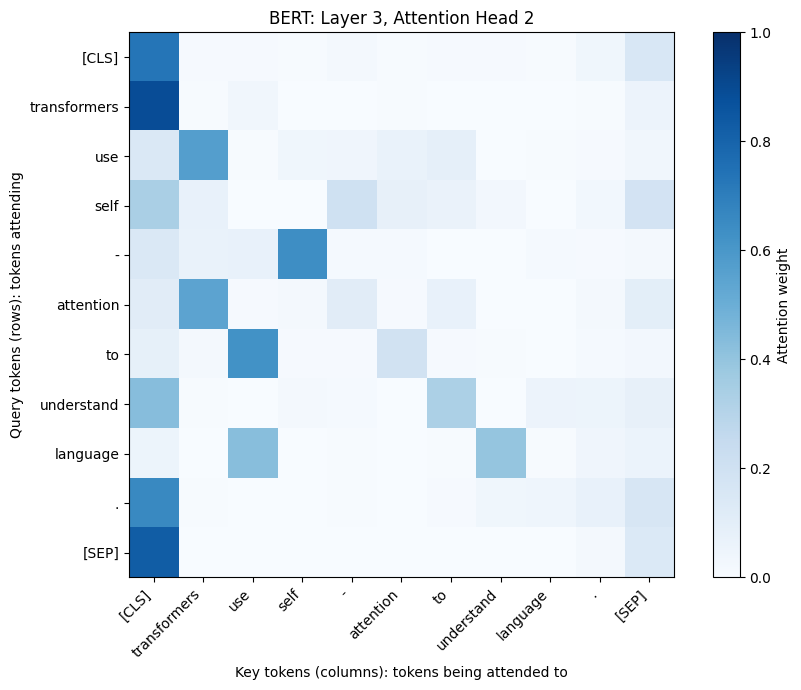

In [6]:
from transformers import AutoTokenizer, BertModel
import torch
import matplotlib.pyplot as plt

# Load pretrained BERT and its tokenizer.
bert_name = "bert-base-uncased"
bert_tokenizer = AutoTokenizer.from_pretrained(bert_name)
bert_model = BertModel.from_pretrained(bert_name, attn_implementation="eager")
bert_model.eval()

# Questions 1 and 2: layers, heads per layer, and total heads.
num_layers = bert_model.config.num_hidden_layers
heads_per_layer = bert_model.config.num_attention_heads
total_heads = num_layers * heads_per_layer

print("Number of Transformer layers:", num_layers)
print("Number of attention heads per layer:", heads_per_layer)
print("Total number of attention heads:", total_heads)

# Question 3: third layer (index 2), second head (index 1).
text = "Transformers use self-attention to understand language."
bert_inputs = bert_tokenizer(text, return_tensors="pt")
bert_tokens = bert_tokenizer.convert_ids_to_tokens(bert_inputs["input_ids"][0])

with torch.no_grad():
    bert_outputs = bert_model(**bert_inputs, output_attentions=True)

# Each layer's attention has shape (batch, heads, tokens, tokens).
attention_matrix = bert_outputs.attentions[2][0, 1].cpu()

print("\nTokens:", bert_tokens)
print("Third-layer, second-head attention matrix shape:", tuple(attention_matrix.shape))
print("Attention weights (third layer, second head):\n", attention_matrix)

# Optional visualization to make the attention matrix easier to interpret.
plt.figure(figsize=(9, 7))
plt.imshow(attention_matrix.numpy(), cmap="Blues", vmin=0, vmax=1)
plt.xticks(range(len(bert_tokens)), bert_tokens, rotation=45, ha="right")
plt.yticks(range(len(bert_tokens)), bert_tokens)
plt.xlabel("Key tokens (columns): tokens being attended to")
plt.ylabel("Query tokens (rows): tokens attending")
plt.title("BERT: Layer 3, Attention Head 2")
plt.colorbar(label="Attention weight")
plt.tight_layout()
plt.show()


### Question 4: What do the rows and columns represent?

- **Rows (query tokens):** Each row corresponds to a token that is attending to other tokens in the input sentence.
- **Columns (key tokens):** Each column corresponds to a token that can receive attention from the row token.
- **Cell values:** The number at row *i*, column *j* indicates how much attention token *i* gives to token *j* in the selected attention head. Larger values indicate greater attention weight.
- **Row sums:** Each row sums to approximately **1** because attention weights are normalized with softmax. The matrix includes special tokens such as `[CLS]` and `[SEP]`.

**Expected model configuration:** `bert-base-uncased` has **12 Transformer layers** and **12 attention heads per layer**, giving **12 × 12 = 144 total attention heads**. The third layer and second head use zero-based indices **2** and **1**, respectively.
